In [7]:
import os
import sys
import subprocess
import multiprocessing
import numpy as np

# local modules
sys.path.insert(0, "./")
from estimator import estimatorFunction
from count import estimate_correlation_length_from_trajs
from avg_std import *

# Input and outputs  
phsm = "./phsm/phsm" # phsm program
datafile = "./example-input/colvars.npy"
initialpath = "./example-input/centers2D.txt"
output_root = os.path.abspath("rate_results")

## PHSM input parameters
SIGMA = [1, 1]
NSTATE = 20
R_values = [1.74] # can be a list 
tang_values = [0.24] # can be a list
EPSILON = 1e-16
ORTHOGONALITY = 1
COMPLEXITY = 1
GRAVITY = 20
MONOTONIC = -1
ACCURACY = 0.05
ITERATIONS = 1000

## Simulation paramters 
kb = 0.0019872041
T = 300
kbT = kb * T
dt_ = 0.001
## rate matrix paramters 
unit_phys = 1 # reserved 
First, Second = 0, NSTATE - 1 # initial and target states
stride_k = 1
NBOOT = 30
nproc= 1
lag_values = [1, 3, 5, 7] + list(range(10, 39, 5)) + list(range(40, 70, 10)) + [75, 100]
estimator = "PA" # estimator
# FE file for MLE
FE_file = "./example-input/fe.err"
FE_file = os.path.abspath(FE_file)
FE_ = np.loadtxt(FE_file, usecols=[1]) if estimator == "MLE-pi" else None

datafile = os.path.abspath(datafile)
initialpath = os.path.abspath(initialpath)
phsm = os.path.abspath(phsm)
data = np.load(datafile, mmap_mode="r") if datafile.endswith(".npy") else np.loadtxt(datafile)
N = len(data)
T1 = len(np.loadtxt(initialpath))
del data

for R in R_values:
    r = R
    for tang in tang_values:
        if tang > r:
            continue

        outdir = os.path.join(output_root, f"{estimator}_{R}_{tang}")
        os.makedirs(outdir, exist_ok=True)
        print(f"Processing R={r}, tang={tang}")

        parameters = f"""SIGMA {' '.join(map(str, SIGMA))}
TEMPERATURE {T}
IMAGES {NSTATE}
COMPLEXITY {COMPLEXITY}
GRAVITY {GRAVITY}
EPSILON {EPSILON}
DELTA {r}
ORTHOGONALITY {ORTHOGONALITY}
THICKNESS {tang}
MONOTONIC {MONOTONIC}
ACCURACY {ACCURACY}
ITERATIONS {ITERATIONS}
PATHFILE phsm.path
SMOOTHPATHFILE phsm.smooth
CLUSTERFILE cluster.npy
"""
        subprocess.run(
            [phsm, "-D", datafile, "-G", initialpath,
             "-p", str(N), "-i", str(T1), "-d", "2"],
            input=parameters, text=True, cwd=outdir, check=True)

        md_trajs_raw = np.load(os.path.join(outdir, "cluster.npy"))[:, 0]
        pieces = np.split(md_trajs_raw, np.where(md_trajs_raw == -1)[0])
        md_dtrajs = [x[x != -1].astype(np.int16) for x in pieces if np.any(x != -1)]
        if not md_dtrajs:
            continue
        correlation_length = int(np.ceil(estimate_correlation_length_from_trajs(md_dtrajs)))

        all_fe_results = []
        all_mfpt_results = []
        all_D_results = []

        for lag in lag_values:
            valid_trajs = [traj for traj in md_dtrajs if len(traj) >= lag]
            if not valid_trajs:
                continue
            block_length = max(correlation_length, lag + 1)
            print(f"Running {NBOOT} bootstraps for lag={lag}")

            bootstrap_args = [
                (iboot, valid_trajs, block_length, lag, dt_, unit_phys, r, tang,
                 NSTATE, First, Second, estimator, FE_, kbT, stride_k)
                for iboot in range(1, NBOOT + 1)]

            if nproc > 1:
                with multiprocessing.Pool(processes=nproc) as pool:
                    results_list = pool.map(estimatorFunction, bootstrap_args)
            else:
                results_list = [estimatorFunction(args) for args in bootstrap_args]

            for fe_res, mfpt_res, D_res in results_list:
                if fe_res:
                    all_fe_results.append(fe_res)
                if mfpt_res:
                    all_mfpt_results.append(mfpt_res)
                if D_res:
                    all_D_results.append(D_res)

        agg_fe = aggregate_results(all_fe_results)
        agg_mfpt = aggregate_results(all_mfpt_results)
        agg_D = aggregate_results(all_D_results)
        linked_masks = build_linked_outlier_masks(agg_fe, agg_D)

        compute_avg_std_fe(agg_fe, outdir, linked_masks)
        compute_avg_std_D(agg_D, outdir, linked_masks)
        mfpt_outputFile = os.path.join(outdir, f"mfpt_{r:.2f}_{tang:.2f}.txt")
        compute_mfpt(agg_mfpt, mfpt_outputFile, linked_masks)
        print(f"Results for {estimator} are in {outdir}")

Processing R=1.74, tang=0.24


Parsing the arguments ...
A 2-dimensional weight map will be imported from /Scr/diship-new/project_scribe/9.code_test1/qgen/example-input/colvars.npy ( 1666656 data points ).
A 2-dimensional initial pathway will be imported from /Scr/diship-new/project_scribe/9.code_test1/qgen/example-input/centers2D.txt ( 20 data points ).
Reading the parameters ...
Sigma_0 = 1
Sigma_1 = 1
TEMPERATURE = 300
20 is the number of points on the path.
1 will be used to scale the dimensionality of the spline.
20 will be used for poles.
epsilon = 1e-16
delta = 1.74
orthogonality method = 1
thickness = 0.24
nothing will be the reference to determine the monotonic progress.
accuracy = 0.05
1000 is the maximum number of iterations.
Path Filename = phsm.path
Smooth Path Filename = phsm.smooth
Cluster Filename = cluster.npy
1666656 data points read.
20 points on the path read.
Clustering begins...
Iteration 1: changed 0.0597543 from last iteration.
Iteration 2: changed 0.019963 from last iteration.
PHSM converged

Running 30 bootstraps for lag=1
Running 30 bootstraps for lag=3
Running 30 bootstraps for lag=5
Running 30 bootstraps for lag=7
Running 30 bootstraps for lag=10
Running 30 bootstraps for lag=15
Running 30 bootstraps for lag=20
Running 30 bootstraps for lag=25
Running 30 bootstraps for lag=30
Running 30 bootstraps for lag=35
Running 30 bootstraps for lag=40
Running 30 bootstraps for lag=50
Running 30 bootstraps for lag=60
Running 30 bootstraps for lag=75
Running 30 bootstraps for lag=100
Results for PA are in /Scr/diship-new/project_scribe/9.code_test1/qgen/rate_results/PA_1.74_0.24


## Plotting

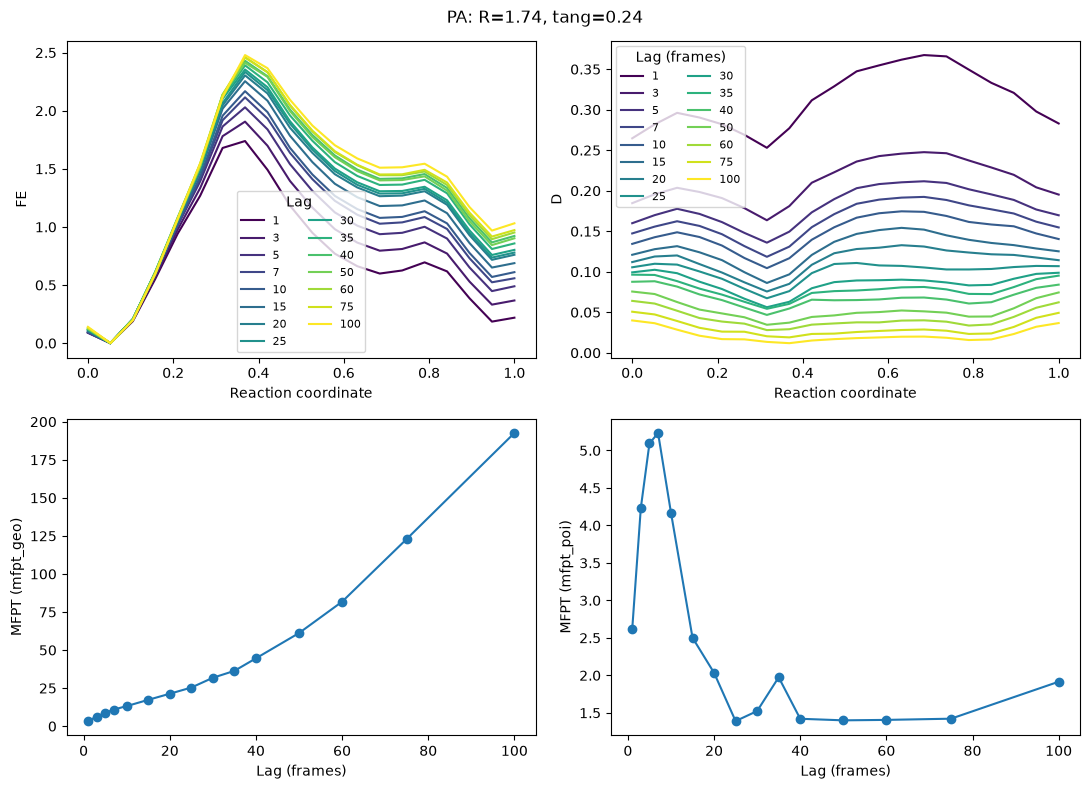

In [8]:
import matplotlib.pyplot as plt

for R in R_values:
    for tang in tang_values:
        if tang > R:
            continue

        outdir = os.path.join(output_root, f"{estimator}_{R}_{tang}")
        mfpt = np.loadtxt(os.path.join(outdir, f"mfpt_{R:.2f}_{tang:.2f}.txt"), ndmin=2)
        colors = plt.cm.viridis(np.linspace(0, 1, len(mfpt)))
        fig, ax = plt.subplots(2, 2, figsize=(11, 8))

        for lag, color in zip(mfpt[:, 2].astype(int), colors):
            fe = np.loadtxt(os.path.join(outdir, f"fe_{R:.2f}_{tang:.2f}_{lag}.txt"))[:, 0]
            D = np.loadtxt(os.path.join(outdir, f"D_{R:.2f}_{tang:.2f}_{lag}.txt"))[:, 0]
            s = np.linspace(0, 1, len(fe))
            ax[0, 0].plot(s, fe, color=color, label=str(lag))
            ax[0, 1].plot(s, D, color=color, label=str(lag))

        ax[0, 0].set(xlabel="Reaction coordinate", ylabel="FE")
        ax[0, 1].set(xlabel="Reaction coordinate", ylabel="D")
        ax[0, 0].legend(title="Lag ", fontsize=8, ncol=2)
        ax[0, 1].legend(title="Lag (frames)", fontsize=8, ncol=2)
        ax[1, 0].plot(mfpt[:, 2], mfpt[:, 3], "o-")
        ax[1, 1].plot(mfpt[:, 2], mfpt[:, 7], "o-")
        ax[1, 0].set(xlabel="Lag (frames)", ylabel="MFPT (mfpt_geo)")
        ax[1, 1].set(xlabel="Lag (frames)", ylabel="MFPT (mfpt_poi)")
        fig.suptitle(f"{estimator}: R={R}, tang={tang}")
        fig.tight_layout()
        plt.show()